# 02. Splits and baselines

**Goal.** (1) Lock the train / validation / test roles for every record and prove they leak nothing. (2) Measure the simple baselines every
model must beat.

**Discipline.** Baselines are scored on **validation** predictions only. The outer test groups are not scored here and are not scored until
notebook 08, so nothing seen now can influence a choice that the test result is later supposed to judge.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("training").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import Ridge

from common import (FEATURES, GROUPS, RESULTS, SPLITS, SEED, environment, group_bootstrap, load, log_run, log_signed, make_splits,
                    metrics, paired_diff_bootstrap)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
d = load().set_index("record_id", drop=False)
print(environment())

{'python': '3.11.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'seed': 20261018, 'data_hash': '2a23bdaa674b', 'splits_hash': ''}


## 1. The split design

- Five student-disjoint **groups** (A-E). Each group is the **test** group once (outer loop).
- For each test group, each of the other four is the **validation** group once, and the remaining three are **train** (inner loop).
  That gives 5 x 4 = 20 train / validation / test combinations.
- **Synthetic** records are training-only, and only when **both** parents are in training groups; otherwise they are `excluded`.

In [2]:
splits = make_splits(d)
splits.to_csv(SPLITS, index=False)
print(f"wrote {SPLITS.name}: {len(splits)} rows, {splits.groupby(['outer_test', 'inner_val']).ngroups} combinations")

role = splits.join(d[["source", "label_source", "group"]], on="record_id")
table = (role.groupby(["outer_test", "inner_val", "role"])
         .apply(lambda g: pd.Series({"real": (g.source == "real").sum(), "synthetic": (g.source == "synthetic").sum(),
                                     "rated": (g.label_source == "rater").sum()}), include_groups=False)
         .unstack("role").fillna(0).astype(int))
table

wrote splits.csv: 14880 rows, 20 combinations


real                synthetic                   rated               
role                 excluded test train val  excluded test train val excluded test train val
outer_test inner_val                                                                         
A          B                0   71    45  28       554    0    46   0        0    7     9   4
           C                0   71    52  21       524    0    76   0        0    7     9   4
           D                0   71    57  16       519    0    81   0        0    7    10   3
           E                0   71    65   8       480    0   120   0        0    7    11   2
B          A                0   28    45  71       554    0    46   0        0    4     9   7
           C                0   28    95  21       318    0   282   0        0    4    12   4
           D                0   28   100  16       323    0   277   0        0    4    13   3
           E                0   28   108   8       260    0   340   0        0    4    14   2
C          A                0   21    52  71       524    0    76   0        0    4     9   7
           B                0   21    95  28       318    0   282   0        0    4    12   4
           D                0   21   107  16       258    0   342   0        0    4    13   3
           E                0   21   115   8       149    0   451   0        0    4    14   2
D          A                0   16    57  71       519    0    81   0        0    3    10   7
           B                0   16   100  28       323    0   277   0        0    3    13   4
           C                0   16   107  21       258    0   342   0        0    3    13   4
           E                0   16   120   8       191    0   409   0        0    3    15   2
E          A                0    8    65  71       480    0   120   0        0    2    11   7
           B                0    8   108  28       260    0   340   0        0    2    14   4
           C                0    8   115  21       149    0   451   0        0    2    14   4
           D                0    8   120  16       191    0   409   0        0    2    15   3

## 2. Leakage checks (all must pass)

In [3]:
problems = []
for (test, val), s in role.groupby(["outer_test", "inner_val"]):
    real = s[s.source == "real"]
    train_g = set(real[real.role == "train"].group)
    val_g, test_g = set(real[real.role == "val"].group), set(real[real.role == "test"].group)
    if val_g != {val} or test_g != {test}:
        problems.append((test, val, "wrong validation or test group"))
    if train_g & (val_g | test_g) or val_g & test_g:
        problems.append((test, val, "a group is in two roles"))
    # no student in two roles
    st = real.join(d[["student_id"]], on="record_id").groupby("role").student_id.agg(set)
    if (st.get("train", set()) & st.get("val", set())) or (st.get("train", set()) & st.get("test", set())) or (st.get("val", set()) & st.get("test", set())):
        problems.append((test, val, "a student is in two roles"))
    syn = s[s.source == "synthetic"]
    if (syn.role.isin(["val", "test"])).any():
        problems.append((test, val, "synthetic row in validation or test"))
    kept = syn[syn.role == "train"].join(d[["parents"]], on="record_id")
    for r in kept.itertuples():
        pa, pb = r.parents.split()
        if not ({d.loc[pa, "group"], d.loc[pb, "group"]} <= train_g):
            problems.append((test, val, f"synthetic {r.record_id} has a parent outside the training groups"))
            break
assert not problems, problems
print("OK: no group or student is in two roles; synthetic rows are train-only with both parents in training groups")
print("every real record is test once per its group:", role[(role.source == 'real') & (role.role == 'test')].groupby('record_id').outer_test.nunique().eq(1).all())
print("every real record is validation in exactly 4 combinations:", role[(role.source == 'real') & (role.role == 'val')].groupby('record_id').size().eq(4).all())

OK: no group or student is in two roles; synthetic rows are train-only with both parents in training groups
every real record is test once per its group: True
every real record is validation in exactly 4 combinations: True


## 3. Baselines

All are fitted on the **rated records in the three training groups** only (9-15 records) and predict the rated records in the validation group.

| Baseline | What it is |
|---|---|
| mean / median | Constant: mean or median of the training labels |
| commits (normalised) | No fitting: `log(1+commits) / log(1+largest commit count among training records)`, the "GitHub Insights" view |
| commits (linear) | `a + b * log(1+commits)` fitted on the training labels |
| tasks (linear) | `a + b * tasks_done` (the "Jira" view) |
| ridge (5 features) | Ridge on the five signed-log features; `alpha` chosen by leave-one-out on the training labels |

Each commit and task baseline also has a **+ zero rule** variant: predict 0 when there are no commits.

In [4]:
GOLD = d[d.label_source == "rater"]
X_of = lambda frame: log_signed(frame[FEATURES].astype(float)).to_numpy()
ALPHAS = np.logspace(-2, 3, 11)


def fit_predict(name, train, val, train_real_cc_max):
    y = train.rater_effort.to_numpy()
    if name == "mean":
        return np.full(len(val), y.mean())
    if name == "median":
        return np.full(len(val), np.median(y))
    if name == "commits (normalised)":
        return np.clip(np.log1p(val.E_CC) / np.log1p(train_real_cc_max), 0, 1).to_numpy()
    if name == "commits (linear)":
        b, a = np.polyfit(np.log1p(train.E_CC), y, 1)
        return np.clip(a + b * np.log1p(val.E_CC), 0, 1).to_numpy()
    if name == "tasks (linear)":
        b, a = np.polyfit(train.E_CT, y, 1)
        return np.clip(a + b * val.E_CT, 0, 1).to_numpy()
    if name == "ridge (5 features)":
        X, Xv = X_of(train), X_of(val)
        mu, sd = X.mean(0), X.std(0)
        sd[sd == 0] = 1
        Z, Zv = (X - mu) / sd, (Xv - mu) / sd
        best = min(ALPHAS, key=lambda a: np.mean([abs(Ridge(alpha=a).fit(np.delete(Z, i, 0), np.delete(y, i)).predict(Z[i:i + 1])[0] - y[i]) for i in range(len(y))]))
        return np.clip(Ridge(alpha=best).fit(Z, y).predict(Zv), 0, 1)
    raise ValueError(name)


NAMES = ["mean", "median", "commits (normalised)", "commits (linear)", "tasks (linear)", "ridge (5 features)"]
rows = []
for (test, val), s in role.groupby(["outer_test", "inner_val"]):
    real_train = s[(s.source == "real") & (s.role == "train")].record_id
    train = d.loc[[i for i in real_train if i in GOLD.index]]
    cc_max = d.loc[real_train].E_CC.max()
    v = d.loc[[i for i in s[(s.source == "real") & (s.role == "val")].record_id if i in GOLD.index]]
    for name in NAMES:
        p = fit_predict(name, train, v, cc_max)
        for variant, pp in ((name, p), (name + " + zero rule", np.where(v.E_CC.to_numpy() == 0, 0.0, p))):
            if variant.endswith("zero rule") and name in ("mean", "median", "ridge (5 features)"):
                continue
            for rid, g, y, yhat, cc in zip(v.record_id, v.group, v.rater_effort, pp, v.E_CC):
                rows.append((test, val, variant, rid, g, y, yhat, cc))
pred = pd.DataFrame(rows, columns=["outer_test", "inner_val", "model", "record_id", "group", "y", "pred", "E_CC"])
print(pred.groupby("model").size())
pred.to_csv(RESULTS / "baseline_validation_predictions.csv", index=False)

model
commits (linear)                    80
commits (linear) + zero rule        80
commits (normalised)                80
commits (normalised) + zero rule    80
mean                                80
median                              80
ridge (5 features)                  80
tasks (linear)                      80
tasks (linear) + zero rule          80
dtype: int64


## 4. Baseline results on validation

Each rated record is a validation record in four combinations, so it appears four times per model. Metrics use all those rows; intervals
resample whole groups (2,000 resamples), so a group's records stay together.

In [5]:
summary = []
for model, g in pred.groupby("model"):
    m = metrics(g.y, g.pred)
    lo, hi = group_bootstrap(g.y.to_numpy(), g.pred.to_numpy(), g.group.to_numpy(), lambda y, p: np.mean(np.abs(p - y)), n=1000)
    a = g[g.E_CC > 0]
    summary.append({"model": model, "MAE": m["MAE"], "MAE 95% CI": f"{lo:.3f}-{hi:.3f}", "RMSE": m["RMSE"], "bias": m["bias"],
                    "Pearson": m["pearson"], "Spearman": m["spearman"], "R2": m["R2"], "band within 1": m["band_within_1"],
                    "MAE active only": float(np.abs(a.pred - a.y).mean())})
baselines = pd.DataFrame(summary).set_index("model").sort_values("MAE")
baselines.round(3)

,MAE,MAE 95% CI,RMSE,bias,Pearson,Spearman,R2,band within 1,MAE active only
model,,,,,,,,,
commits (normalised) + zero rule,0.053,0.023-0.070,0.072,-0.019,0.962,0.947,0.917,1.000,0.062
commits (normalised),0.053,0.023-0.070,0.072,-0.019,0.962,0.947,0.917,1.000,0.062
commits (linear) + zero rule,0.057,0.031-0.079,0.079,-0.002,0.949,0.924,0.900,1.000,0.068
commits (linear),0.061,0.037-0.081,0.080,0.001,0.947,0.922,0.897,1.000,0.068
ridge (5 features),0.073,0.043-0.097,0.108,-0.002,0.905,0.874,0.813,0.988,0.086
tasks (linear) + zero rule,0.114,0.043-0.160,0.150,-0.032,0.828,0.815,0.638,0.975,0.134
tasks (linear),0.138,0.072-0.176,0.166,-0.008,0.761,0.757,0.559,0.975,0.134
mean,0.248,0.189-0.329,0.294,-0.018,-0.429,-0.385,-0.394,0.625,0.215
median,0.261,0.196-0.344,0.316,-0.020,-0.332,-0.386,-0.610,0.575,0.227


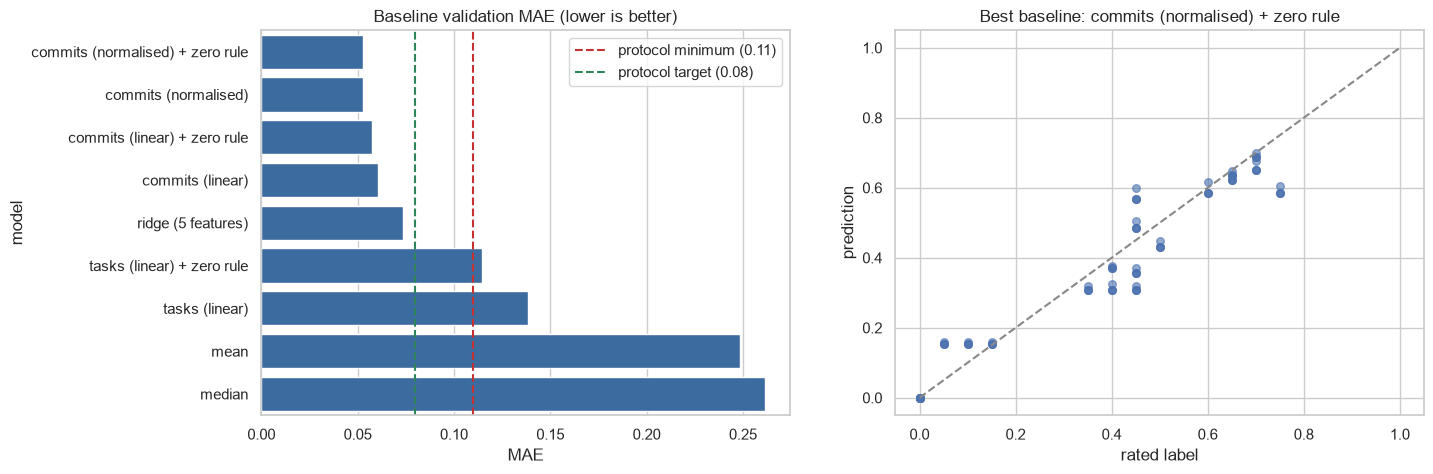

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
order = baselines.index
sns.barplot(x=baselines.MAE, y=order, color="#2b6cb0", ax=axes[0])
axes[0].axvline(0.11, color="#c53030", ls="--", label="protocol minimum (0.11)")
axes[0].axvline(0.08, color="#2f855a", ls="--", label="protocol target (0.08)")
axes[0].set(title="Baseline validation MAE (lower is better)", xlabel="MAE"); axes[0].legend()
best = baselines.index[0]
g = pred[pred.model == best]
axes[1].scatter(g.y, g.pred, s=30, alpha=.6)
axes[1].plot([0, 1], [0, 1], "--", color="#888")
axes[1].set(title=f"Best baseline: {best}", xlabel="rated label", ylabel="prediction")
plt.show()

## 5. How much does the zero rule matter?

A quarter of the real records have no commits, and the rated set contains three of them. Comparing each baseline with and without the rule
shows how much of the apparent skill is just "no commits means zero".

In [7]:
pairs = []
for base in ["commits (normalised)", "commits (linear)", "tasks (linear)"]:
    a, b = pred[pred.model == base].sort_values(["outer_test", "inner_val", "record_id"]), pred[pred.model == base + " + zero rule"].sort_values(["outer_test", "inner_val", "record_id"])
    lo, hi = paired_diff_bootstrap(a.y.to_numpy(), a.pred.to_numpy(), b.pred.to_numpy(), a.group.to_numpy(), n=1000)
    pairs.append({"baseline": base, "MAE without": float(np.abs(a.pred - a.y).mean()), "MAE with zero rule": float(np.abs(b.pred.to_numpy() - b.y.to_numpy()).mean()),
                  "difference (without - with), 95% CI": f"{lo:.3f} to {hi:.3f}"})
pd.DataFrame(pairs).set_index("baseline").round(3)

,MAE without,MAE with zero rule,"difference (without - with), 95% CI"
baseline,,,
commits (normalised),0.053,0.053,0.000 to 0.000
commits (linear),0.061,0.057,0.000 to 0.009
tasks (linear),0.138,0.114,0.000 to 0.073


## 6. Bar to beat, and log

The result that matters for the protocol: models in notebooks 04-05 must beat **commit count alone** on validation with a paired interval
that excludes zero (and by at least 10% to meet the target), and Ridge is the model any complex model must beat.

In [8]:
ref = baselines.loc["commits (linear)"]
print(f"commits (linear): validation MAE {ref.MAE:.3f}; a model needs MAE below {ref.MAE * 0.9:.3f} to be 10% better")
print(f"ridge (5 features): validation MAE {baselines.loc['ridge (5 features)'].MAE:.3f}")
for model, row in baselines.iterrows():
    log_run("02_splits_and_baselines", model, "validation, pooled over 20 combinations",
            {"MAE": round(row.MAE, 4), "RMSE": round(row.RMSE, 4), "pearson": round(row.Pearson, 4), "spearman": round(row.Spearman, 4),
             "bias": round(row.bias, 4), "MAE_active": round(row["MAE active only"], 4)})
print("logged to results/runs.csv")

commits (linear): validation MAE 0.061; a model needs MAE below 0.055 to be 10% better
ridge (5 features): validation MAE 0.073


logged to results/runs.csv


## 7. Reading the results

*Written after the run; see the table above.* The questions this notebook answers:

1. Is commit count alone already close to the protocol minimum (MAE 0.11)? If yes, the extra features have little left to add.
2. Does Ridge on all five features beat commit count alone by a margin larger than the group-bootstrap interval?
3. How much of every baseline's score comes from the zero rule?

These answers set what "clearly better" has to mean in notebooks 04-05.

Next: **03. Preprocessing and features**.